# Temporal transfer synthesis (Work 5)

Question: what do the existing temporal results show when the four comparisons are kept apart (reference transfer, later description, later representation, broader rediscovery), and do three checks on saved outputs (factor ranking, kernel scale, membership overlap) plus the held-out yearly-factor association say anything beyond the Ideas and Work 4 numbers?

Plan: `plan.md` v2.1, §5 steps 0 to 8. `TEMPORAL_TRANSFER_SYNTHESIS_BUILDS=pilot` runs all_history 2008 and last_3 2011; `all` runs the 11 builds. Nothing is fitted: frozen factors, cutoffs, rules, probes and saved yearly units are only read or encoded. Per-row values stay in `private/` on Fiji.

In [1]:
import json
import math
import os
import pickle
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display

import concept_candidates as cc
import concept_regions as cr
import temporal_transfer_synthesis as ts
from concept_study import loading, paths
from concept_subgroup_drift_pilot import encode_with_reference_sae, load_reference_sae, load_yearly_sae

ALL_BUILDS = [("all_history", 2008), ("all_history", 2009), ("all_history", 2010), ("all_history", 2011),
              ("all_history", 2012), ("all_history", 2013), ("last_3", 2010), ("last_3", 2011),
              ("last_3", 2012), ("last_3", 2013), ("r1", 2007)]
BUILD_SETS = {"pilot": [("all_history", 2008), ("last_3", 2011)], "all": ALL_BUILDS}
BUILD_SET = os.environ.get("TEMPORAL_TRANSFER_SYNTHESIS_BUILDS", "pilot")
BUILDS = BUILD_SETS[BUILD_SET]
COLLAPSE_BUILDS = [("r1", 2007), ("all_history", 2008)]
TRANSFER_YEARS = ts.TRANSFER_YEARS
REPRESENTATION_ONLY_YEAR = ts.REPRESENTATION_ONLY_YEAR
ALL_YEARS = (*TRANSFER_YEARS, REPRESENTATION_ONLY_YEAR)
PRIMARY_POOL = "literal"
DEVICE = "cuda"
EXPORT_ROOT = Path("~/rpi-runs/SAE-TCAV/pilot-ideas-followups").expanduser()
OUTPUT = Path(os.environ.get("RPI_OUT_DIR", paths.OUTPUT / f"extensions/temporal_transfer_synthesis/{BUILD_SET}")).expanduser()
PRIVATE = OUTPUT / "private"
PROJECT = paths.CODE_ROOT
STEP_SECONDS = {}
ERRORS = []
print("builds:", BUILD_SET, BUILDS)
print("output:", OUTPUT)

builds: all [('all_history', 2008), ('all_history', 2009), ('all_history', 2010), ('all_history', 2011), ('all_history', 2012), ('all_history', 2013), ('last_3', 2010), ('last_3', 2011), ('last_3', 2012), ('last_3', 2013), ('r1', 2007)]
output: ~/SAE-TCAV/stats/concept_agreement_study/extensions/temporal_transfer_synthesis/full


In [2]:
def stop(message):
    raise RuntimeError(message)


def save_table(frame, name):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)


def save_figure(figure, name):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(OUTPUT / f"{name}.png", dpi=120)
    plt.show()


def anchor(build, reference, name, observed, expected, atol):
    return {**ts.anchor_row(name, observed, expected, atol), "build": build, "reference": reference}


def stop_failed_builds(anchor_rows, step):
    # Plan §5 failure behaviour: a build with a failed exact anchor stops its checks; it is recorded and the
    # other builds continue. Returns the stopped (build, reference) keys.
    failed = [row for row in anchor_rows if not row["passed"]]
    stopped = sorted({(row["build"], row["reference"]) for row in failed})
    for key in stopped:
        names = ts.failed_anchors([row for row in failed if (row["build"], row["reference"]) == key])
        ERRORS.append({"build": key[0], "reference": key[1], "step": step,
                       "error": f"{len(names)} anchors failed, first: {names[0]}"[:400]})
        BUILD_STATE.pop(key, None)
    return stopped


def drop_stopped(table, stopped):
    if not len(table) or not stopped:
        return table
    keys = list(zip(table.build, table.reference))
    return table[[key not in stopped for key in keys]]


def check_year(year, reference):
    # plan decision 2: the reference year, then 2012-2014 after it, and 2015 as its own column
    return int(year) == int(reference) or (int(year) > int(reference) and int(year) in ALL_YEARS)


# Fix 14: year labels come from the module (before 2012, 2012-2014, 2015 separate, reference)
year_group = ts.year_group


def time_step(name, started):

    STEP_SECONDS[name] = round(time.monotonic() - started, 2)


def tag(*parts):
    """Key of the Work 3 classifier archive: parts joined by |, with / replaced by ~ (as Work 4)."""
    return "|".join(str(p).replace("/", "~") for p in parts)


def saved_declared(classifiers, name, pool):
    """The declared classifier saved by Work 3: status, support, and coef and intercept when measured."""
    status = str(classifiers[tag(name, pool, "declared_status")])
    saved = {"status": status, "support": [int(v) for v in classifiers[tag(name, pool, "declared_support")]]}
    if status == "measured":
        saved["coef"] = classifiers[tag(name, pool, "declared_coef")]
        saved["intercept"] = float(classifiers[tag(name, pool, "declared_intercept")])
    return saved

## Step 0. Hash gate and provenance
Question: are the frozen inputs the ones plan §10 names? A mismatch on a gated input stops the run before anything is loaded. Other hashes are recorded.

In [3]:
started = time.monotonic()
REGION_FILES = paths.OUTPUT / "extensions/concept_regions/full"
CANDIDATE_FILES = paths.OUTPUT / "extensions/concept_candidates/full"
CONCEPT_FILES = sorted((paths.PATIENT_TABLE / "concepts").glob("*.npz"))
GATE_EXPECTED = {
    "concept_candidates.py": "2ecc6a9df44fe191c9af21ac105ad38b38ec9b699969e821ac9586d711cbef36",
    "concept_regions.py": "f8525670cd09514b131f404485e39557ea8a1b568479d2b167873b9c10180820",
    "concept_study/loading.py": "4d488ecee708ac19569eb091cd19c2cb46f3e8f43c804e6705f0ae2f62ff0b78",
    "cmr_common.py": "eb2f43940cf29693d45f07b23abbb1b376b61e29604b59fdb3294b2e00963198",
    "cav_classifiers.npz": "894387f5d529a1d074871f8f3a70046226b6cc73dcbf6dd4e6bcebbcc85f6362",
    "patient_table/index.json": "46a5434c39671ef452307bf72b99711cd54bd22d2dcc58a2af3815820aaecbe1",
    "patient_table/concepts (combined)": "ab19a0efdf0af70da09690fc2559267384d919f6a61b5e7f416d1bedfde28f44",
    "temporal robustness population (prepared.pkl)": "c8804591c93087241b9533dce77dd54b2f1e77b23a36400527459cfa8f99add7",
    "region_probes.pkl": "e5d72cc03f18541d219682b52f26253db587aac996184df1325617268d8942ca",
    "concept_regions run.json": "0b182aecbecff4e6b777669f8e5cc18ff06e932bf7e03db369cbad1050f6faea",
    "membership.csv": "b79571faf5d06b669e56aedd5b30c1ec4e3fb8ce785dc2a733b97a8fdfd6c4a6",
    "trajectories.csv": "9931db1edccc55260ed2c699cbea9921b3440dd184aa4431cfcd5913cfa26bbc",
    "recognition.csv": "31de8d517120e6005bcc0150424e577d03c5dca7cb492d03d569f2c555a38caa",
    "score_quantiles.csv": "672d4e79f2a588e85ed38c6a67f2fab29b84bd26c6539adea7460dc4a7d187cc",
    "coverage.csv": "14be3290abe163a8e1194780621b5cc0d7a5e97ea1f0f99e2cdd7dbdca07a779",
    "changes_by_build.csv": "1dfa1518a66ce4e1c85f32ec91dd99978603fb2c1ea69110a1cb0f9a505fbde4",
    "summary_by_build.csv": "20b58719039d2b19b0659e123576f3ad43380a5748c2058b6c2481623a4f9fa9",
    "summary_by_years_since_reference.csv": "c82e84f802321403aafbc59ded609f88693112315ca2a79c4e724090ab066f04",
    "tuning.csv": "6921a7cb5902fad7145986a12c747a34b34f68dd737d6188f8c7bbec3906aa0d",
}
GATE_PATHS = {
    "concept_candidates.py": PROJECT / "concept_candidates.py",
    "concept_regions.py": PROJECT / "concept_regions.py",
    "concept_study/loading.py": PROJECT / "concept_study/loading.py",
    "cmr_common.py": PROJECT / "cmr_common.py",
    "cav_classifiers.npz": CANDIDATE_FILES / "cav_classifiers.npz",
    "patient_table/index.json": paths.PATIENT_TABLE / "index.json",
    "temporal robustness population (prepared.pkl)": paths.POPULATION,
    "region_probes.pkl": REGION_FILES / "private/region_probes.pkl",
    "concept_regions run.json": REGION_FILES / "run.json",
    "membership.csv": REGION_FILES / "membership.csv",
    "trajectories.csv": REGION_FILES / "trajectories.csv",
    "recognition.csv": REGION_FILES / "recognition.csv",
    "score_quantiles.csv": REGION_FILES / "score_quantiles.csv",
    "coverage.csv": REGION_FILES / "coverage.csv",
    "changes_by_build.csv": REGION_FILES / "changes_by_build.csv",
    "summary_by_build.csv": REGION_FILES / "summary_by_build.csv",
    "summary_by_years_since_reference.csv": REGION_FILES / "summary_by_years_since_reference.csv",
    "tuning.csv": REGION_FILES / "tuning.csv",
}
actual = {name: cr.sha256(path) for name, path in GATE_PATHS.items()}
actual["patient_table/concepts (combined)"] = ts.combined_hash(CONCEPT_FILES)
ts.check_hashes(GATE_EXPECTED, actual)
display(pd.DataFrame([{"input": name, "sha256": actual[name]} for name in GATE_EXPECTED]))
EXPORT_FILES = sorted(EXPORT_ROOT.glob("evaluate-*/evaluate-*.json"))
RECORDED = {
    "concept_subgroup_drift_pilot.py": cr.sha256(PROJECT / "concept_subgroup_drift_pilot.py"),
    "concept_study/paths.py": cr.sha256(PROJECT / "concept_study/paths.py"),
    "concept_study/patient_table.py": cr.sha256(PROJECT / "concept_study/patient_table.py"),
    "alternative_bases/agreement_by_years_since_reference.csv": cr.sha256(
        paths.OUTPUT / "extensions/alternative_bases/agreement_by_years_since_reference.csv"),
    "ideas exports": {str(path.relative_to(EXPORT_ROOT)): cr.sha256(path) for path in EXPORT_FILES},
    "repo modules imported": {ts.relative_to_project(m.__file__, PROJECT, Path.home()): cr.sha256(m.__file__) for m in list(sys.modules.values())
                              if str(getattr(m, "__file__", None) or "").startswith(str(PROJECT))
                              and "site-packages" not in str(m.__file__)
                              and not str(m.__file__).startswith(str(PROJECT / ".venv"))},
}
print("ideas exports found:", len(EXPORT_FILES), "(plan: 27)")
print("free disk GiB:", round(shutil.disk_usage(PROJECT).free / 2**30, 1))
if torch.cuda.is_available():
    free_gpu, total_gpu = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), "| free MiB", int(free_gpu // 2**20), "of", int(total_gpu // 2**20))
else:
    print("no CUDA visible: steps 4 to 7 stop; nothing falls back to CPU silently")
time_step("step0_gate", started)

,input,sha256
0,concept_candidates.py,2ecc6a9df44fe191c9af21ac105ad38b38ec9b699969e8...
1,concept_regions.py,f8525670cd09514b131f404485e39557ea8a1b568479d2...
2,concept_study/loading.py,4d488ecee708ac19569eb091cd19c2cb46f3e8f43c804e...
3,cmr_common.py,eb2f43940cf29693d45f07b23abbb1b376b61e29604b59...
4,cav_classifiers.npz,894387f5d529a1d074871f8f3a70046226b6cc73dcbf6d...
5,patient_table/index.json,46a5434c39671ef452307bf72b99711cd54bd22d2dcc58...
6,patient_table/concepts (combined),ab19a0efdf0af70da09690fc2559267384d919f6a61b5e...
7,temporal robustness population (prepared.pkl),c8804591c93087241b9533dce77dd54b2f1e77b23a3640...
8,region_probes.pkl,e5d72cc03f18541d219682b52f26253db587aac996184d...
9,concept_regions run.json,0b182aecbecff4e6b777669f8e5cc18ff06e932bf7e03d...


ideas exports found: 27 (plan: 27)
free disk GiB: 97.4
GPU: NVIDIA GeForce RTX 2080 | free MiB 7845 of 7972


## Step 0b. Inputs and the single draw set
Question: which patients does each bootstrap draw resample? One draw set serves every check (plan decision 6): a patient has the same count in every build, year and check, and draws come from the population's ids, not the patient table's.

In [4]:
started = time.monotonic()
inputs = loading.open_inputs()
population = inputs["population"]
POPULATION_IDS = np.asarray(population["patient_id"]).astype(str)
UNIQUE_IDS = np.unique(POPULATION_IDS)
DRAW_COUNTS = cc.patient_weights(UNIQUE_IDS, cc.BOOTSTRAP_SEEDS).astype(np.int32)
print("population patients:", len(UNIQUE_IDS), "| draw counts:", DRAW_COUNTS.shape,
      "| seeds", cc.BOOTSTRAP_SEEDS[0], "to", cc.BOOTSTRAP_SEEDS[-1])
time_step("step0b_inputs", started)

population patients: 5636 | draw counts: (500, 5636) | seeds 3001 to 3500


## Step 1. Read the Ideas exports
Question: do the 27 exports hold the counts the research reports (2034 ambiguity, 225 unmatched, no single-candidate entries; 750 available and 246 insufficient yearly descriptions), and how far do duplicate exports of one build disagree? Each export is read, flattened and released in turn.

In [5]:
started = time.monotonic()
PANEL_EXPORT = {ts.export_path(EXPORT_ROOT, build, reference): (build, reference) for build, reference in ALL_BUILDS}
PANEL_CONCEPTS = {loading.concept_key(i["build"], i["reference"], i["family"]) for i in inputs["inventory"]}
COUNTS = {"entries": 0, "families": 0, "matching": {}, "description": {}}
PRIMARY = {"family": [], "description": [], "matching": [], "member": []}
COPIES = {"family": [], "matching": []}
for path in EXPORT_FILES:
    export = json.loads(path.read_text())
    label = export["build"]
    family = ts.family_year_rows(export, label)
    description = ts.description_rows(export, label)
    matching = ts.matching_rows(export, label)
    members = ts.member_rows(export, label)
    del export
    COUNTS["families"] += len(family)
    COUNTS["entries"] += len(matching)
    for row in description:
        COUNTS["description"][row["status"]] = COUNTS["description"].get(row["status"], 0) + 1
    for row in matching:
        COUNTS["matching"][row["mechanical_status"]] = COUNTS["matching"].get(row["mechanical_status"], 0) + 1
    for build, reference in ALL_BUILDS:
        prefix = f"{build}/{reference}/"
        if PANEL_EXPORT.get(path) == (build, reference):
            PRIMARY["family"] += [row for row in family if row["concept"].startswith(prefix)]
            PRIMARY["description"] += [row for row in description if row["concept"].startswith(prefix)]
            PRIMARY["matching"] += [row for row in matching if row["concept"].startswith(prefix)]
            PRIMARY["member"] += [row for row in members if row["concept"].startswith(prefix)]
        elif any(row["concept"].startswith(prefix) for row in family):
            COPIES["family"].append({"build": build, "reference": reference, "file": str(path.relative_to(EXPORT_ROOT)),
                                     "rows": [row for row in family if row["concept"].startswith(prefix)]})
            COPIES["matching"].append({"build": build, "reference": reference, "file": str(path.relative_to(EXPORT_ROOT)),
                                       "rows": [row for row in matching if row["concept"].startswith(prefix)]})
ANCHOR_COUNTS = pd.DataFrame([
    {"count": "matching entries, 27 exports", "observed": COUNTS["entries"], "expected": 2259},
    {"count": "candidate split/ambiguity", "observed": COUNTS["matching"].get(ts.AMBIGUOUS, 0), "expected": 2034},
    {"count": "unmatched", "observed": COUNTS["matching"].get(ts.UNMATCHED, 0), "expected": 225},
    {"count": "single candidate", "observed": COUNTS["matching"].get(ts.SINGLE, 0), "expected": 0},
    {"count": "yearly descriptions available", "observed": COUNTS["description"].get("available", 0), "expected": 750},
    {"count": "yearly descriptions insufficient", "observed": COUNTS["description"].get("insufficient positive yearly fit/tune support", 0), "expected": 246},
])
ANCHOR_COUNTS["matches"] = ANCHOR_COUNTS.observed == ANCHOR_COUNTS.expected
display(ANCHOR_COUNTS)
save_table(ANCHOR_COUNTS, "anchors_ideas_counts")
panel_with_records = {row["concept"] for row in PRIMARY["family"]} & PANEL_CONCEPTS
print("panel concepts with Ideas records:", len(panel_with_records), "of", len(PANEL_CONCEPTS), "(panel concepts of all 11 builds)")
time_step("step1_exports", started)

,count,observed,expected,matches
0,"matching entries, 27 exports",2259,2259,True
1,candidate split/ambiguity,2034,2034,True
2,unmatched,225,225,True
3,single candidate,0,0,True
4,yearly descriptions available,750,750,True
5,yearly descriptions insufficient,246,246,True


panel concepts with Ideas records: 92 of 95 (panel concepts of all 11 builds)


In [6]:
started = time.monotonic()
DUPLICATE_GAPS = []
for build, reference in BUILDS:
    primary = [row for row in PRIMARY["family"] if row["build"] == build and row["reference"] == reference]
    for copy in [c for c in COPIES["family"] if (c["build"], c["reference"]) == (build, reference)]:
        DUPLICATE_GAPS.append({"build": build, "reference": reference, "copy file": copy["file"],
                               "largest gap (rows, R rows, A rows, retention)": ts.duplicate_gaps(
                                   primary, copy["rows"], ["concept", "year"], ["retention", "rows", "R_rows", "A_rows"]),
                               "primary rows": len(primary), "copy rows": len(copy["rows"])})
DUPLICATE_TABLE = pd.DataFrame(DUPLICATE_GAPS)
display(DUPLICATE_TABLE)
save_table(DUPLICATE_TABLE, "duplicate_export_gaps")
time_step("step1b_duplicates", started)

,build,reference,copy file,"largest gap (rows, R rows, A rows, retention)",primary rows,copy rows
0,all_history,2008,evaluate-last_3/evaluate-2008.json,0.0,48,48
1,all_history,2009,evaluate-last_3/evaluate-2009.json,0.0,70,70
2,r1,2007,evaluate-all_history/evaluate-2007.json,0.0,36,36
3,r1,2007,evaluate-last_3/evaluate-2007.json,0.0,36,36


## Step 2. Synthesis tables
Question: what does each of the four comparisons contain, with its denominator and status? Reference transfer, later description and later representation are separate tables; 2015 has its own column everywhere.

In [7]:
started = time.monotonic()
INVENTORY = pd.DataFrame([
    {"comparison": "reference transfer (Ideas values)", "quantity": "retention and row counts of the family member, per family-year", "denominator": "family-year records of the 27 exports (panel concepts only)", "source": "evaluate-*.json temporal.families and temporal.members", "uncertainty and conditioning": "none per record (counts); per-seed retention spread in seed_spread.csv", "status": "measured; 3 concepts with no Ideas record kept as status rows"},
    {"comparison": "reference transfer (Work 4 probes)", "quantity": "AUROC and recall of the region and linear probes, changes from reference", "denominator": "concept-years of the 95 SAE concepts", "source": "concept_regions run (trajectories.csv, membership.csv)", "uncertainty and conditioning": "paired patient draws (Work 4); conditions on frozen probes, rules and cutoffs; fit variability not included", "status": "measured (values in atlas_work4_probes.csv); 14 region probe rows unsupported at reference"},
    {"comparison": "reference transfer (other bases)", "quantity": "agreement by years since reference, five bases (SAE, PCA, k-means, random, rule CAV)", "denominator": "reference builds r1 2007, all_history 2008-2009, last_3 2010-2013 (its README)", "source": "alternative_bases/agreement_by_years_since_reference.csv (copied, unchanged)", "uncertainty and conditioning": "its own joint patient and concept bootstrap (per the extension)", "status": "measured; no calendar year (years since reference only)"},
    {"comparison": "later description (Ideas)", "quantity": "yearly description status (available or insufficient support)", "denominator": "family-year records", "source": "temporal.families yearly_description", "uncertainty and conditioning": "none (counts); refit variability not measured", "status": "available or insufficient kept as recorded"},
    {"comparison": "later representation (Ideas matching)", "quantity": "top-3 Pearson candidates, gap, possible merges, mechanical status", "denominator": "member entries per yearly SAE", "source": "temporal.families yearly_representations", "uncertainty and conditioning": "none; same-seed Pearson inflated by shared initialisation; no between-seed control saved", "status": "mechanical statuses only; factor indices are pointers"},
    {"comparison": "broader rediscovery", "quantity": "independent later candidates", "denominator": "none exists", "source": "none", "uncertainty and conditioning": "unmeasured", "status": "unmeasured"},
    {"comparison": "check (a) factor ranking", "quantity": "activation and linear AUROC for R, P(A given R), P(A given not R), changes, paired difference, activation quantiles by R group", "denominator": "concept-years of reference, 2012-2014 and 2015", "source": "patient_table evaluation rows with the frozen declared classifier", "uncertainty and conditioning": "paired population-patient draws (500); conditions on frozen factor, cutoff, rule and declared classifier; fit variability not included", "status": "measured or undefined (no rule patients)"},
    {"comparison": "check (b) kernel scale", "quantity": "score and kernel term quantiles, squared distances, ratio to reference year", "denominator": "probe-years of the 92 region probes", "source": "frozen region probes (private, Fiji)", "uncertainty and conditioning": "deterministic quantities of frozen probes; no interval", "status": "measured or no region probe"},
    {"comparison": "check (c) patient-level overlap", "quantity": "P(N given M), P(N given not M), P(N given R), contrast, changes", "denominator": "rule rows per concept-year (region misses M, other reading N)", "source": "frozen probes, declared classifier, patient_table in_A and in_R", "uncertainty and conditioning": "paired population-patient draws; conditions on reference-year cutoffs, rules and probes", "status": "measured or undefined with reason"},
    {"comparison": "yearly-factor association", "quantity": "held-out AUROC of matched yearly factors and the frozen member", "denominator": "family-member-seed-year entries with an Ideas entry", "source": "saved yearly SAE units encoded on evaluation rows", "uncertainty and conditioning": "paired population-patient draws; conditions on export identity and profile anchors; fit variability of yearly SAE not included", "status": "measured or unmeasured with reason"},
])
save_table(INVENTORY, "inventory")
OTHER_BASES = pd.read_csv(paths.OUTPUT / "extensions/alternative_bases/agreement_by_years_since_reference.csv")
OTHER_BASES.insert(0, "source", "alternative_bases; reference builds r1 2007, all_history 2008-2009, last_3 2010-2013 (README)")
save_table(OTHER_BASES, "reference_transfer_other_bases")
W4_TRAJECTORIES = pd.read_csv(REGION_FILES / "trajectories.csv")
W4_MEMBERSHIP = pd.read_csv(REGION_FILES / "membership.csv")
W4_QUANTITIES = ["auroc:region", "auroc:linear", "auroc:tuned", "auroc:region - linear", "change auroc:region", "change auroc:linear"]
W4_MEMBERSHIP_QUANTITIES = ["recall:region", "recall:linear", "members:region", "members:linear", "p_a_rule"]
W4_VALUES = pd.concat([
    W4_TRAJECTORIES[(W4_TRAJECTORIES.source == "sae") & (W4_TRAJECTORIES.pool == PRIMARY_POOL)
                    & (W4_TRAJECTORIES.population == "all") & W4_TRAJECTORIES.quantity.isin(W4_QUANTITIES)],
    W4_MEMBERSHIP[(W4_MEMBERSHIP.source == "sae") & (W4_MEMBERSHIP.pool == PRIMARY_POOL)
                  & (W4_MEMBERSHIP.population == "all") & W4_MEMBERSHIP.quantity.isin(W4_MEMBERSHIP_QUANTITIES)],
], ignore_index=True)
W4_VALUES = W4_VALUES[[any(str(c).startswith(f"{b}/{r}/") for b, r in BUILDS) for c in W4_VALUES.concept]]
W4_VALUES = W4_VALUES[[check_year(int(y), int(str(c).split("/")[1])) for y, c in zip(W4_VALUES.year, W4_VALUES.concept)]]
W4_VALUES = W4_VALUES[["build", "reference", "concept", "year", "stage", "quantity", "point", "low", "high", "undefined_fraction"]]
W4_VALUES["year group"] = [year_group(int(y), int(r)) for y, r in zip(W4_VALUES.year, W4_VALUES.reference)]
save_table(W4_VALUES, "atlas_work4_probes")
ATLAS_WORK4 = W4_VALUES
FAMILY = pd.DataFrame(PRIMARY["family"])
FAMILY["years_since_reference"] = FAMILY.year - FAMILY.reference
FAMILY["column"] = np.where(FAMILY.year == REPRESENTATION_ONLY_YEAR, "2015 separate", "transfer years")
FAMILY["status"] = "measured"
TRANSFER_COLUMNS = ["build", "reference", "concept", "year", "years_since_reference", "column", "status", "rows",
                    "R_rows", "A_rows", "retention", "idea1_status", "idea2_status"]
ABSENT_ROWS = []
for build, reference in BUILDS:
    have = set(FAMILY.loc[(FAMILY.build == build) & (FAMILY.reference == reference), "concept"])
    for item in [i for i in inputs["inventory"] if (i["build"], i["reference"]) == (build, reference)]:
        name = loading.concept_key(build, reference, item["family"])
        if name in have:
            continue
        for year in (*TRANSFER_YEARS, REPRESENTATION_ONLY_YEAR):
            ABSENT_ROWS.append({"build": build, "reference": reference, "concept": name, "year": year,
                                "years_since_reference": year - reference,
                                "column": "2015 separate" if year == REPRESENTATION_ONLY_YEAR else "transfer years",
                                "status": "no Ideas record (not eligible for either idea)"})
REFERENCE_TRANSFER = pd.concat([FAMILY[TRANSFER_COLUMNS], pd.DataFrame(ABSENT_ROWS)], ignore_index=True)
save_table(REFERENCE_TRANSFER, "reference_transfer")
ABSENT_CONCEPTS = len({(r["build"], r["reference"], r["concept"]) for r in ABSENT_ROWS})
print("concepts with no Ideas record (status rows kept):", ABSENT_CONCEPTS)
ATLAS_HISTORICAL = (REFERENCE_TRANSFER.groupby(["build", "reference", "years_since_reference", "column", "status"])
                    .agg(concepts=("concept", "size"), median_retention=("retention", "median")).reset_index())
save_table(ATLAS_HISTORICAL, "atlas_historical")
DESCRIPTION = pd.DataFrame(PRIMARY["description"])
DESCRIPTION["column"] = np.where(DESCRIPTION.year == REPRESENTATION_ONLY_YEAR, "2015 separate", "transfer years")
save_table(DESCRIPTION.groupby(["build", "reference", "column", "status"]).size().rename("count").reset_index(),
           "later_description")
MATCHING = pd.DataFrame(PRIMARY["matching"])
MATCHING["years_since_reference"] = MATCHING.year - MATCHING.reference
MATCHING["column"] = np.where(MATCHING.year == REPRESENTATION_ONLY_YEAR, "2015 separate", "transfer years")
MATCHING_AUDIT = (MATCHING.groupby(["build", "reference", "years_since_reference", "mechanical_status"])
                  .agg(entries=("concept", "size"), pearson_1_median=("pearson_1", "median"),
                       gap_median=("gap_1_2", "median"), merges_total=("merges", "sum")).reset_index())
MATCHING_AUDIT["between_seed_control"] = "not saved (no between-seed activation control found in the export's correspondence block)"
save_table(MATCHING_AUDIT, "matching_audit")
MEMBERS = pd.DataFrame(PRIMARY["member"])
MEMBERS["year group"] = [year_group(int(y), int(r)) for y, r in zip(MEMBERS.year, MEMBERS.reference)]
SEED_SPREAD = (MEMBERS.groupby(["build", "reference", "concept", "year", "year group"])
               .agg(seeds=("seed", "nunique"), retention_min=("retention", "min"), retention_max=("retention", "max"),
                    A_rows=("A_rows", "first"), R_rows=("R_rows", "first")).reset_index())
SEED_SPREAD["retention spread (max minus min over seeds)"] = SEED_SPREAD.retention_max - SEED_SPREAD.retention_min
save_table(SEED_SPREAD, "seed_spread")
DICTIONARY_SIZE = len(json.loads(ts.export_path(EXPORT_ROOT, *BUILDS[0]).read_text())["temporal"]["all_dictionary_factors"][0]["all_factors"]["positive_prevalence"])
CANDIDATE_COVERAGE = pd.DataFrame(ts.candidate_coverage(PRIMARY["matching"], DICTIONARY_SIZE))
save_table(CANDIDATE_COVERAGE, "candidate_coverage")
time_step("step2_tables", started)

concepts with no Ideas record (status rows kept): 3


## Step 3. Load each build and check the exact anchors
Question: do the rebuilt objects equal the patient table, and do the export's family-year counts equal the patient table counts? Exact anchors per concept: rule mask equal to the patient table `in_R`, row counts equal. Per family-year: the export's `rows` and `R_rows` equal the patient table counts. A mismatch stops that build only.

In [8]:
started = time.monotonic()
CONCEPT_FILE = {entry["concept"]: entry["file"] for entry in json.load(open(paths.PATIENT_TABLE / "index.json"))["concepts"]}
BUILD_STATE, CONCEPT_ANCHORS = {}, []
for build, reference in BUILDS:
    items = [i for i in inputs["inventory"] if (i["build"], i["reference"]) == (build, reference)]
    try:
        bases = cc.load_build_two_modes(inputs, build, reference, items[0]["roles"])
        ev = bases["evaluate"]
        E = np.flatnonzero(ev["roles"] == "evaluation")
        frames = {}
        for item in items:
            name = loading.concept_key(build, reference, item["family"])
            if name not in CONCEPT_FILE:
                continue
            frame = np.load(paths.PATIENT_TABLE / "concepts" / CONCEPT_FILE[name])
            unit_ev = loading.concept_unit(inputs, ev, item)
            frames[name] = {"in_R": np.asarray(frame["in_R"], bool), "in_A": np.asarray(frame["in_A"], bool),
                            "activation": np.asarray(frame["activation"], float), "unit": unit_ev}
            CONCEPT_ANCHORS.append({"build": build, "reference": reference, "concept": name,
                                    "rows equal": len(frame["in_R"]) == len(E),
                                    "in_R equal": bool(np.array_equal(frame["in_R"], unit_ev["rule_mask"][E])),
                                    "activation gap (descriptive)": float(np.max(np.abs(
                                        np.asarray(frame["activation"], float) - np.asarray(unit_ev["activation"], float)[E])))})
        mine = pd.DataFrame(CONCEPT_ANCHORS).query("build == @build and reference == @reference")
        if not (mine["rows equal"].all() and mine["in_R equal"].all()):
            stop(f"{build} {reference}: exact anchor failed; this build stops")
        for row in [r for r in PRIMARY["family"] if (r["build"], r["reference"]) == (build, reference)]:
            if row["concept"] not in frames:
                continue
            in_year = ev["years"][E] == row["year"]
            if int(in_year.sum()) != row["rows"] or int(frames[row["concept"]]["in_R"][in_year].sum()) != row["R_rows"]:
                stop(f"{build} {reference}: family-year {row['concept']} {row['year']} counts differ from the patient table")
        BUILD_STATE[(build, reference)] = {"ev": ev, "E": E, "items": items, "frames": frames}
    except Exception as error:
        ERRORS.append({"build": build, "reference": reference, "step": "step3", "error": f"{type(error).__name__}: {error}"[:400]})
        print("ERROR", build, reference, ERRORS[-1]["error"])
ANCHOR_CONCEPTS = pd.DataFrame(CONCEPT_ANCHORS)
save_table(ANCHOR_CONCEPTS, "anchors_concept_load")
display(ANCHOR_CONCEPTS.groupby(["build", "reference"])[["rows equal", "in_R equal"]].all())
print("builds loaded:", sorted(BUILD_STATE), "| errors:", len(ERRORS))
time_step("step3_load", started)

~/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rows equal  in_R equal
build       reference                        
all_history 2008             True        True
            2009             True        True
            2010             True        True
            2011             True        True
            2012             True        True
            2013             True        True
last_3      2010             True        True
            2011             True        True
            2012             True        True
            2013             True        True
r1          2007             True        True

builds loaded: [('all_history', 2008), ('all_history', 2009), ('all_history', 2010), ('all_history', 2011), ('all_history', 2012), ('all_history', 2013), ('last_3', 2010), ('last_3', 2011), ('last_3', 2012), ('last_3', 2013), ('r1', 2007)] | errors: 0


In [9]:
started = time.monotonic()
EXPORT_ROW_ANCHORS = []
for (build, reference), state in BUILD_STATE.items():
    ev, E = state["ev"], state["E"]
    for row in [r for r in PRIMARY["family"] if (r["build"], r["reference"]) == (build, reference)]:
        if row["concept"] not in state["frames"]:
            continue
        in_year = ev["years"][E] == row["year"]
        observed_rows = int(in_year.sum())
        observed_R = int(state["frames"][row["concept"]]["in_R"][in_year].sum())
        EXPORT_ROW_ANCHORS.append({"build": build, "reference": reference, "concept": row["concept"], "year": row["year"],
                                   "anchor": f"{row['concept']} {row['year']} export rows and R rows equal the patient table",
                                   "observed": [observed_rows, observed_R], "expected": [row["rows"], row["R_rows"]],
                                   "max_gap": float(max(abs(observed_rows - row["rows"]), abs(observed_R - row["R_rows"]))),
                                   "atol": 0.0, "passed": observed_rows == row["rows"] and observed_R == row["R_rows"]})
EXPORT_ROW_TABLE = pd.DataFrame(EXPORT_ROW_ANCHORS)
save_table(EXPORT_ROW_TABLE, "anchors_export_rows")
print("export family-year anchors:", len(EXPORT_ROW_TABLE), "| passed:", int(EXPORT_ROW_TABLE.passed.sum()) if len(EXPORT_ROW_TABLE) else 0)
time_step("step3b_export_rows", started)

export family-year anchors: 470 | passed: 470


## Step 4. Check (a): does the factor's activation keep ranking R, paired with the declared linear probe?
Question: per concept and year, how do the activation and linear AUROCs for R change from the reference year, and how does that change compare, draw by draw, with P(A | R) and P(A | not R)? Anchor: linear AUROC and P(A | R) point, low and high equal Work 4 within 1e-12 (same draw set).

In [10]:
if not torch.cuda.is_available():
    stop("CUDA unavailable: stop and report (no silent CPU fallback)")
started = time.monotonic()
CLASSIFIERS = np.load(CANDIDATE_FILES / "cav_classifiers.npz")
TRAJECTORIES = pd.read_csv(REGION_FILES / "trajectories.csv")
MEMBERSHIP = pd.read_csv(REGION_FILES / "membership.csv")
TRAJ_AUROC = TRAJECTORIES[(TRAJECTORIES.source == "sae") & (TRAJECTORIES.pool == PRIMARY_POOL)
                          & (TRAJECTORIES.population == "all") & (TRAJECTORIES.quantity == "auroc:linear")]
MEM_PA = MEMBERSHIP[(MEMBERSHIP.source == "sae") & (MEMBERSHIP.pool == PRIMARY_POOL)
                    & (MEMBERSHIP.population == "all") & (MEMBERSHIP.quantity == "p_a_rule")]
CHANGE_MEASURES = ["change_auroc_activation", "change_auroc_linear", "change_p_a_given_r", "change_p_a_given_not_r",
                   "paired_auroc_difference"]
ACTIVATION_LEVELS = (0.05, 0.25, 0.5, 0.75, 0.95)
CONDITIONS_CHANGE = ("Intervals: 2.5 to 97.5 percent over the 500 paired population-patient bootstrap draws (seeds 3001 to 3500). "
                     "Conditions on the reference-year frozen factor, cutoff, rule and declared linear classifier (no refit) and on the "
                     "evaluation rows of each year. Fit variability of the factor, rule and classifier is not included.")
FACTOR_RANKING, FACTOR_ANCHORS = [], []
PAIRED = {}
for (build, reference), state in BUILD_STATE.items():
    ev, E = state["ev"], state["E"]
    X = np.asarray(ev["embeddings"])[E]
    for item in state["items"]:
        name = loading.concept_key(build, reference, item["family"])
        if name not in state["frames"]:
            continue
        frame = state["frames"][name]
        saved = saved_declared(CLASSIFIERS, name, PRIMARY_POOL)
        linear = X @ saved["coef"] + saved["intercept"] if saved["status"] == "measured" else np.full(len(E), np.nan)
        activation = np.asarray(frame["unit"]["activation"], float)[E]
        years = {}
        for year in sorted(set(ev["years"][E].tolist())):
            if not check_year(year, reference):
                continue
            mask = ev["years"][E] == year
            years[int(year)] = {"patient_ids": ev["patients"][E][mask], "in_R": frame["in_R"][mask],
                                "in_A": frame["in_A"][mask], "activation": activation[mask], "linear": linear[mask]}
        if reference not in years:
            FACTOR_RANKING.append(ts.status_row({"build": build, "reference": reference, "concept": name, "year": reference},
                                                "no reference-year evaluation rows",
                                                ["auroc_activation", "auroc_linear", "p_a_given_r", "p_a_given_not_r"]))
            continue
        result = ts.auroc_changes(years, reference, DRAW_COUNTS, POPULATION_IDS)
        for year, measured in result["per_year"].items():
            draws = measured["draws"]
            R_rows = int(years[year]["in_R"].sum())
            row = {"build": build, "reference": reference, "concept": name, "year": year,
                   "years_since_reference": year - reference, "year group": year_group(year, reference),
                   "linear_status": saved["status"], "rows": len(years[year]["in_R"]), "R_rows": R_rows,
                   "status": ts.NO_RULE_PATIENTS if R_rows == 0 else "measured",
                   "zero_share_R": measured["zero_share"]["R"], "zero_share_not_R": measured["zero_share"]["not_R"]}
            for label, selected in (("in rule", years[year]["in_R"]), ("not in rule", ~years[year]["in_R"])):
                for level in ACTIVATION_LEVELS:
                    row[f"activation q{int(level * 100):02d} {label}"] = (
                        float(np.quantile(years[year]["activation"][selected], level)) if selected.any() else math.nan)
            for quantity in ("auroc_activation", "auroc_linear", "p_a_given_r", "p_a_given_not_r"):
                interval = cc.interval(draws[quantity])
                row[quantity] = measured["point"][quantity]
                row[f"{quantity} low"] = interval["low"]
                row[f"{quantity} high"] = interval["high"]
            changes = result["changes"][year]
            for measure in CHANGE_MEASURES:
                interval = cc.interval(changes[measure])
                row[f"{measure} low"] = interval["low"]
                row[f"{measure} high"] = interval["high"]
                row[f"{measure} defined fraction"] = 1 - interval["undefined_fraction"]
                PAIRED.setdefault((build, reference, year), {}).setdefault(measure, {})[name] = changes[measure]
            FACTOR_RANKING.append(row)
            if saved["status"] == "measured":
                trajectory = TRAJ_AUROC[(TRAJ_AUROC.concept == name) & (TRAJ_AUROC.year == year)]
                if len(trajectory):
                    t = trajectory.iloc[0]
                    FACTOR_ANCHORS.append(anchor(build, reference, f"{name} {year} linear AUROC point/low/high",
                        [row["auroc_linear"], row["auroc_linear low"], row["auroc_linear high"]],
                        [t.point, t.low, t.high], 1e-12))
            membership = MEM_PA[(MEM_PA.concept == name) & (MEM_PA.year == year)]
            if len(membership):
                m = membership.iloc[0]
                FACTOR_ANCHORS.append(anchor(build, reference, f"{name} {year} P(A|R) point/low/high",
                    [row["p_a_given_r"], row["p_a_given_r low"], row["p_a_given_r high"]],
                    [m.point, m.low, m.high], 1e-12))
STOPPED_A = stop_failed_builds(FACTOR_ANCHORS, "step 4 check (a)")
FACTOR_TABLE = pd.DataFrame(FACTOR_RANKING) if FACTOR_RANKING else pd.DataFrame(columns=["build", "reference", "concept", "year", "status"])
FACTOR_TABLE = drop_stopped(FACTOR_TABLE, STOPPED_A)
FACTOR_TABLE["conditions on"] = CONDITIONS_CHANGE
ANCHOR_A = pd.DataFrame(FACTOR_ANCHORS)
save_table(FACTOR_TABLE, "factor_ranking")
save_table(ANCHOR_A, "anchors_check_a")
POSITION_ROWS, PANEL_ROWS = [], []
for (build, reference, year), measures in sorted(PAIRED.items()):
    if year == reference or (build, reference) in STOPPED_A:
        continue
    group = year_group(year, reference)
    for measure, by_concept in measures.items():
        matrix = np.vstack(list(by_concept.values()))
        medians = cr.median_by_draw(matrix)
        interval = cc.interval(medians["median"])
        PANEL_ROWS.append({"build": build, "reference": reference, "year": year, "year group": group,
                           "years_since_reference": year - reference, "measure": measure, "concepts": matrix.shape[0],
                           "draws": matrix.shape[1], "median low": interval["low"], "median high": interval["high"],
                           "median of the draw medians": float(np.nanmedian(medians["median"])) if np.isfinite(medians["median"]).any() else math.nan,
                           "conditions on": CONDITIONS_CHANGE})
    positions = cr.position_counts(np.vstack(list(measures["paired_auroc_difference"].values())))
    POSITION_ROWS.append({"build": build, "reference": reference, "year": year, "year group": group,
                          "years_since_reference": year - reference,
                          "measure": "paired_auroc_difference (activation change minus linear change)",
                          **{position: positions[position] for position in ("above 0", "below 0", "spans 0", "identical", "undefined")},
                          "non-degenerate": positions["above 0"] + positions["below 0"] + positions["spans 0"],
                          "chance each side": positions["chance each side"], "conditions on": CONDITIONS_CHANGE})
POSITIONS = pd.DataFrame(POSITION_ROWS)
save_table(POSITIONS, "factor_ranking_positions")
save_table(pd.DataFrame(PANEL_ROWS), "factor_ranking_panel")
if len(POSITIONS):
    by_group = POSITIONS.groupby(["build", "reference", "year group"])[["above 0", "below 0", "spans 0", "identical", "undefined", "non-degenerate"]].sum().reset_index()
    by_group["chance each side (2.5 % of non-degenerate)"] = 0.025 * by_group["non-degenerate"]
    by_group["conditions on"] = CONDITIONS_CHANGE
    save_table(by_group, "factor_ranking_positions_by_group")
print("concept-years:", len(FACTOR_TABLE), "| anchors:", len(ANCHOR_A),
      "| failed:", int((~ANCHOR_A.passed).sum()) if len(ANCHOR_A) else 0, "| builds stopped:", STOPPED_A)
time_step("step4_factor_ranking", started)

concept-years: 415 | anchors: 816 | failed: 0 | builds stopped: []


In [11]:
started = time.monotonic()
SUMMARY_ROWS = []
for (build, reference, group), frame in FACTOR_TABLE[FACTOR_TABLE["year group"].notna()].groupby(["build", "reference", "year group"]):
    if group == "reference":
        continue
    SUMMARY_ROWS.append({"build": build, "reference": reference, "year group": group,
                         "years since reference": f"{int(frame.years_since_reference.min())}-{int(frame.years_since_reference.max())}",
                         "build-years rows": len(frame),
                         "concepts defined (activation AUROC)": int(frame.auroc_activation.notna().sum()),
                         "median auroc activation": float(frame.auroc_activation.median()),
                         "median auroc linear": float(frame.auroc_linear.median()),
                         "median p_a_given_r": float(frame.p_a_given_r.median()),
                         "median p_a_given_not_r": float(frame.p_a_given_not_r.median()),
                         "median zero share R": float(frame.zero_share_R.median()),
                         "median zero share not R": float(frame.zero_share_not_R.median())})
SUMMARY = pd.DataFrame(SUMMARY_ROWS)
save_table(SUMMARY, "factor_ranking_summary")
display(SUMMARY)
time_step("step4b_summary", started)

,build,reference,year group,years since reference,build-years rows,concepts defined (activation AUROC),median auroc activation,median auroc linear,median p_a_given_r,median p_a_given_not_r,median zero share R,median zero share not R
0,all_history,2008,2012-2014,4-6,18,18,0.956415,0.971194,0.000000,0.001859,0.000000,0.822184
1,all_history,2008,2015 separate,7-7,6,6,0.932899,0.971865,0.008475,0.000000,0.053251,0.892842
2,all_history,2009,2012-2014,3-5,30,29,0.980831,0.974994,0.800000,0.023891,0.000000,0.477934
3,all_history,2009,2015 separate,6-6,10,9,0.991688,0.956800,0.428571,0.022568,0.000000,0.470956
4,all_history,2010,2012-2014,2-4,24,24,0.956810,0.980819,0.640000,0.014246,0.000000,0.639711
5,all_history,2010,2015 separate,5-5,8,8,0.947459,0.956086,0.350000,0.008453,0.000000,0.656219
6,all_history,2011,2012-2014,1-3,21,20,0.977103,0.949403,0.775000,0.027950,0.000000,0.476341
7,all_history,2011,2015 separate,4-4,7,6,0.975089,0.934322,0.833333,0.083333,0.000000,0.362637
8,all_history,2012,2012-2014,1-2,22,22,0.951489,0.975005,0.757143,0.037639,0.000000,0.620758
9,all_history,2012,2015 separate,3-3,11,11,0.944094,0.973896,0.360000,0.000000,0.000000,0.658986


## Step 5. Check (b): score scale and kernel distances of the region probes
Question: is the region probe's score collapse in the two collapse builds a kernel-scale effect, that is, do the distances to the support vectors grow relative to the probe's own reference year? The probe is not refitted. Anchors: the torch score equals `decision_function` (1e-9); region recall point, low and high and members at 0 equal `membership.csv` (1e-12). Per-row values stay in `private/`.

In [12]:
started = time.monotonic()
with open(REGION_FILES / "private/region_probes.pkl", "rb") as handle:
    PROBES = pickle.load(handle)["probes"]
TUNING = pd.read_csv(REGION_FILES / "tuning.csv")
SCORE_Q = pd.read_csv(REGION_FILES / "score_quantiles.csv")
SCORE_Q = SCORE_Q[(SCORE_Q.source == "sae") & (SCORE_Q.pool == PRIMARY_POOL) & (SCORE_Q.probe == "region")]
CHOSEN = TUNING[(TUNING.pool == PRIMARY_POOL) & (TUNING.probe == "region") & (TUNING.chosen == True)]
PROBE_STATUS = "no region probe (unsupported at reference)"
QUANTILE_LEVELS = (0.05, 0.25, 0.5, 0.75, 0.95)
KERNEL_QUANTITIES = ["score", "kernel term k", "gamma_sq_all", "gamma_sq_positive"]
KERNEL_VALUES = ["width_multiplier", "preprocessing", "C", "gamma", "intercept b", "support_vectors", "year group"] + [
    f"{q} q{int(level * 100):02d} {label}" for q in KERNEL_QUANTITIES for level in QUANTILE_LEVELS for label in ("in rule", "not in rule")]
KERNEL_ROWS, KERNEL_ANCHORS = [], []
for (build, reference), state in BUILD_STATE.items():
    ev, E = state["ev"], state["E"]
    X_all = np.asarray(ev["embeddings"])[E]
    years_here = [y for y in sorted(set(ev["years"][E].tolist())) if check_year(y, reference)]
    for item in state["items"]:
        name = loading.concept_key(build, reference, item["family"])
        if name not in state["frames"]:
            continue
        probe = PROBES.get((build, reference, name, PRIMARY_POOL), {}).get("region")
        if probe is None:
            for year in years_here:
                KERNEL_ROWS.append(ts.status_row({"build": build, "reference": reference, "concept": name,
                                                  "year": int(year), "group": "all", "year group": year_group(year, reference)},
                                                 PROBE_STATUS, KERNEL_VALUES))
            continue
        svc = probe.steps[-1][1]
        chosen = CHOSEN[(CHOSEN.build == build) & (CHOSEN.reference == reference) & (CHOSEN.concept == name)]
        scaled = probe.steps[0][0] == "scale"
        tuning_matches = (len(chosen) == 1 and float(chosen.C.iloc[0]) == float(svc.C)
                          and scaled == (chosen.preprocessing.iloc[0] == "standardised"))
        width = float(chosen.width_multiplier.iloc[0]) if tuning_matches else "unmeasured: tuning row differs"
        preprocessing = "standardised" if scaled else "raw"
        frame = state["frames"][name]
        private = {}
        for year in years_here:
            mask = ev["years"][E] == year
            X = X_all[mask]
            kernel = ts.kernel_terms(probe, X)
            in_R = frame["in_R"][mask]
            weights = cr.draw_counts_for_rows(DRAW_COUNTS, POPULATION_IDS, ev["patients"][E][mask])
            gap = ts.decision_gap(probe, X)
            KERNEL_ANCHORS.append(anchor(build, reference, f"{name} {year} decision_function gap", [gap], [0.0], 1e-9))
            work4_scores = cr.decision_scores(probe, X)
            for group_name, selected in (("in rule", in_R), ("not in rule", ~in_R)):
                if not selected.any() or year not in (reference, *ALL_YEARS):
                    continue
                saved_quantiles = SCORE_Q[(SCORE_Q.build == build) & (SCORE_Q.reference == reference)
                                          & (SCORE_Q.concept == name) & (SCORE_Q.year == year) & (SCORE_Q.group == group_name)]
                observed_quantiles = cr.score_quantiles(work4_scores, in_R)[group_name]
                expected_quantiles = (saved_quantiles[["q05", "q25", "q50", "q75", "q95"]].iloc[0].values
                                      if len(saved_quantiles) else np.full(5, np.nan))
                KERNEL_ANCHORS.append(anchor(build, reference, f"{name} {year} score quantiles {group_name} (Work 4 path)",
                                             observed_quantiles, expected_quantiles, 1e-12))
            recall_draws = cr.recall_by_draw(in_R, kernel["score"], weights)
            interval = cc.interval(recall_draws)
            recall_point = float(cr.recall_by_draw(in_R, kernel["score"], np.ones((1, len(in_R))))[0])
            members_point = float(np.sum(kernel["score"] > 0))
            saved = MEMBERSHIP[(MEMBERSHIP.source == "sae") & (MEMBERSHIP.pool == PRIMARY_POOL) & (MEMBERSHIP.population == "all")
                               & (MEMBERSHIP.concept == name) & (MEMBERSHIP.year == year)]
            saved_recall = saved[saved.quantity == "recall:region"]
            saved_members = saved[saved.quantity == "members:region"]
            if len(saved_recall):
                s_row = saved_recall.iloc[0]
                KERNEL_ANCHORS.append(anchor(build, reference, f"{name} {year} recall:region point/low/high",
                    [recall_point, interval["low"], interval["high"]], [s_row.point, s_row.low, s_row.high], 1e-12))
            if len(saved_members):
                KERNEL_ANCHORS.append(anchor(build, reference, f"{name} {year} members:region", [members_point],
                                             [saved_members.iloc[0].point], 0.0))
            for group, selected in (("in rule", in_R), ("not in rule", ~in_R)):
                if not selected.any():
                    continue
                row = {"build": build, "reference": reference, "concept": name, "year": int(year),
                       "year group": year_group(year, reference), "group": group, "status": "measured",
                       "width_multiplier": width, "preprocessing": preprocessing, "C": float(svc.C),
                       "gamma": float(svc._gamma), "intercept b": float(svc.intercept_[0]),
                       "support_vectors": int(len(svc.support_vectors_))}
                kernel_arrays = {"score": kernel["score"], "kernel term k": kernel["kernel_term"],
                                 "gamma_sq_all": kernel["gamma_sq_distance_all"],
                                 "gamma_sq_positive": kernel["gamma_sq_distance_positive"]}
                for quantity in KERNEL_QUANTITIES:
                    values = kernel_arrays[quantity][selected]
                    for level in QUANTILE_LEVELS:
                        row[f"{quantity} q{int(level * 100):02d} {group}"] = float(np.quantile(values, level))
                KERNEL_ROWS.append(row)
            private[f"{year}_score"] = kernel["score"]
            private[f"{year}_in_R"] = in_R
        PRIVATE.mkdir(parents=True, exist_ok=True)
        np.savez(PRIVATE / f"row_scores_{build}_{reference}_{item['family'].replace('/', '~').replace(':', '-').replace(',', '-')}.npz", **private)
STOPPED_B = stop_failed_builds(KERNEL_ANCHORS, "step 5 check (b)")
KERNEL_TABLE = pd.DataFrame(KERNEL_ROWS) if KERNEL_ROWS else pd.DataFrame(columns=["build", "reference", "concept", "year", "group", "status"])
KERNEL_TABLE = drop_stopped(KERNEL_TABLE, STOPPED_B)
KERNEL_ANCHOR_TABLE = pd.DataFrame(KERNEL_ANCHORS)
save_table(KERNEL_TABLE, "kernel_scale")
save_table(KERNEL_ANCHOR_TABLE, "anchors_check_b")
print("anchor rows:", len(KERNEL_ANCHOR_TABLE), "| failed:", int((~KERNEL_ANCHOR_TABLE.passed).sum()) if len(KERNEL_ANCHOR_TABLE) else 0,
      "| builds stopped:", STOPPED_B, "| probe-unsupported rows:", int((KERNEL_TABLE.status == PROBE_STATUS).sum()) if len(KERNEL_TABLE) else 0)
time_step("step5_kernel", started)

anchor rows: 2000 | failed: 0 | builds stopped: [] | probe-unsupported rows: 14


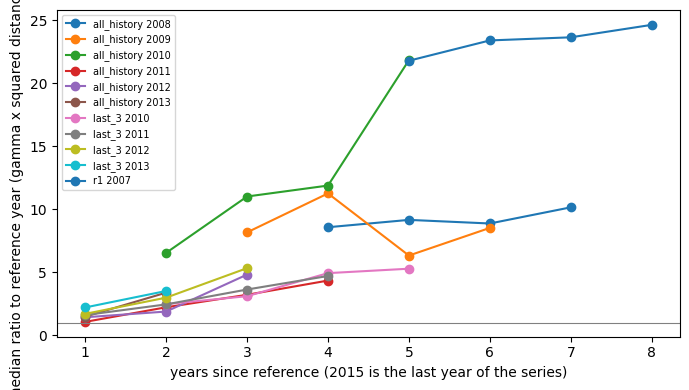

In [13]:
started = time.monotonic()
RATIO_ROWS = []
measured = KERNEL_TABLE[(KERNEL_TABLE.group == "in rule") & (KERNEL_TABLE.status == "measured")] if len(KERNEL_TABLE) else KERNEL_TABLE
if len(measured):
    for (build, reference, name), rows in measured.groupby(["build", "reference", "concept"]):
        if reference not in set(rows.year):
            continue
        records = {int(year): {"build": build, "reference": reference, "concept": name, "year": int(year),
                               "year group": year_group(year, reference), "years_since_reference": int(year) - reference}
                   for year in rows.year}
        for quantity in ("gamma_sq_all", "gamma_sq_positive"):
            keys = [f"{quantity} q{int(level * 100):02d} in rule" for level in QUANTILE_LEVELS]
            values = {int(r.year): r[keys].to_numpy(dtype=float) for _, r in rows.iterrows()}
            ratios = ts.ratio_to_reference(values, reference)
            for year, ratio in ratios.items():
                for level, value in zip(QUANTILE_LEVELS, ratio):
                    records[year][f"ratio {quantity} q{int(level * 100):02d}"] = float(value)
        RATIO_ROWS.extend(records.values())
RATIO_TABLE = pd.DataFrame(RATIO_ROWS)
save_table(RATIO_TABLE, "kernel_distance_ratios")
if len(RATIO_TABLE):
    figure, axis = plt.subplots(figsize=(7, 4))
    for (build, reference), group in RATIO_TABLE[RATIO_TABLE["year group"] != "reference"].groupby(["build", "reference"]):
        medians = group.groupby("years_since_reference")["ratio gamma_sq_all q50"].median()
        axis.plot(medians.index, medians.values, marker="o", label=f"{build} {reference}")
    axis.axhline(1.0, color="grey", lw=0.8)
    axis.set_xlabel("years since reference (2015 is the last year of the series)")
    axis.set_ylabel("median ratio to reference year (gamma x squared distance, q50)")
    axis.legend(fontsize=7)
    save_figure(figure, "kernel_distance_ratio")
time_step("step5b_ratios", started)

## Step 6. Check (c): is the region's recall loss the same effect as the probe-membership drift?
Question: among the R rows the region misses, are they the ones the linear probe also misses (primary reading), or the ones that leave A (extra)? Rank correlations are descriptive, with n; undefined cells keep their reason.

In [14]:
started = time.monotonic()
MEM_WIDE = (MEMBERSHIP[(MEMBERSHIP.source == "sae") & (MEMBERSHIP.pool == PRIMARY_POOL) & (MEMBERSHIP.population == "all")]
            .pivot_table(index=["build", "reference", "concept", "year"], columns="quantity", values="point", aggfunc="first")
            .reset_index())
MEM_WIDE = MEM_WIDE[[check_year(int(y), int(r)) for y, r in zip(MEM_WIDE.year, MEM_WIDE.reference)]]
REFERENCE_ROWS = MEM_WIDE[MEM_WIDE.year == MEM_WIDE.reference].set_index(["build", "reference", "concept"])
CHANGE_COLUMNS = ["members:region", "members:linear", "recall:linear", "jaccard:region-linear", "p_a_rule"]
keys = pd.MultiIndex.from_frame(MEM_WIDE[["build", "reference", "concept"]])
for column in ["recall:region", *CHANGE_COLUMNS]:
    if column in MEM_WIDE.columns and column in REFERENCE_ROWS.columns:
        MEM_WIDE[f"change {column}"] = MEM_WIDE[column] - REFERENCE_ROWS[column].reindex(keys).values
MEM_WIDE["year group"] = [year_group(int(y), int(r)) for y, r in zip(MEM_WIDE.year, MEM_WIDE.reference)]
LATER = MEM_WIDE[MEM_WIDE["year group"] != "reference"]
RHO_ROWS = []
for (build, reference, group), frame in LATER.groupby(["build", "reference", "year group"]):
    for column in CHANGE_COLUMNS:
        if f"change {column}" in frame:
            RHO_ROWS.append({"view": "per build and year group", "build": build, "reference": reference, "year group": group,
                             "against": column, **ts.rank_correlation(frame["change recall:region"].values, frame[f"change {column}"].values)})
panel_later = LATER[~LATER.set_index(["build", "reference"]).index.isin(COLLAPSE_BUILDS)]
for group, frame in panel_later.groupby("year group"):
    for column in CHANGE_COLUMNS:
        if f"change {column}" in frame:
            RHO_ROWS.append({"view": "panel without collapse builds, per year group", "build": "all", "reference": None,
                             "year group": group, "against": column,
                             **ts.rank_correlation(frame["change recall:region"].values, frame[f"change {column}"].values)})
RHO_TABLE = pd.DataFrame(RHO_ROWS)
display(RHO_TABLE)
save_table(RHO_TABLE, "membership_rank_correlation")
time_step("step6_rank", started)

,view,build,reference,year group,against,rho,n
0,per build and year group,all_history,2008.0,2012-2014,members:region,0.430446,18
1,per build and year group,all_history,2008.0,2012-2014,members:linear,0.477787,18
2,per build and year group,all_history,2008.0,2012-2014,recall:linear,0.263413,18
3,per build and year group,all_history,2008.0,2012-2014,jaccard:region-linear,0.947534,18
4,per build and year group,all_history,2008.0,2012-2014,p_a_rule,0.372971,18
...,...,...,...,...,...,...,...
115,"panel without collapse builds, per year group",all,NaN,2015 separate,members:region,0.423034,79
116,"panel without collapse builds, per year group",all,NaN,2015 separate,members:linear,0.147694,79
117,"panel without collapse builds, per year group",all,NaN,2015 separate,recall:linear,0.497042,79
118,"panel without collapse builds, per year group",all,NaN,2015 separate,jaccard:region-linear,0.748936,79


In [15]:
started = time.monotonic()
OVERLAP_ROWS, TABLE_2X2X2 = [], []
OVERLAP_VALUES = ["p_n_given_m point", "p_n_given_not_m point", "p_n_given_r point", "contrast point",
                  "R_rows R rows", "region_misses R rows", "other_misses R rows"]
READINGS = ("primary: linear non-members", "extra: not in A")
LEVEL_QUANTITIES = ("p_n_given_m", "p_n_given_not_m", "p_n_given_r", "contrast")
CONDITIONS_OVERLAP = ("Intervals: 2.5 to 97.5 percent over the paired population-patient bootstrap draws. Conditions on the "
                      "reference-year frozen cutoff, rule and probes (no refit) and on each year's evaluation rows; the reading is the linear "
                      "probe's non-members (primary) or rule patients not in A (extra). Fit variability is not included.")
LEVEL_CONTRAST, CHANGE_CONTRAST = {}, {}
for (build, reference), state in BUILD_STATE.items():
    ev, E = state["ev"], state["E"]
    X = np.asarray(ev["embeddings"])[E].astype(np.float64)
    years_here = [y for y in sorted(set(ev["years"][E].tolist())) if check_year(y, reference)]
    for item in state["items"]:
        name = loading.concept_key(build, reference, item["family"])
        if name not in state["frames"]:
            continue
        probe = PROBES.get((build, reference, name, PRIMARY_POOL), {}).get("region")
        saved = saved_declared(CLASSIFIERS, name, PRIMARY_POOL)
        if probe is None or saved["status"] != "measured":
            reason = PROBE_STATUS if probe is None else "unmeasured: declared linear classifier not measured (Work 3)"
            for year in years_here:
                for reading in READINGS:
                    OVERLAP_ROWS.append(ts.status_row({"build": build, "reference": reference, "concept": name,
                                                       "year": int(year), "year group": year_group(year, reference), "reading": reading},
                                                      reason, OVERLAP_VALUES))
                TABLE_2X2X2.append(ts.status_row({"build": build, "reference": reference, "concept": name,
                                                  "year": int(year), "year group": year_group(year, reference)}, reason, []))
            continue
        linear_scores = X @ saved["coef"] + saved["intercept"]
        region_scores = cr.decision_scores(probe, X)
        frame = state["frames"][name]
        years_rows = {}
        for year in years_here:
            mask = ev["years"][E] == year
            years_rows[int(year)] = {"patient_ids": ev["patients"][E][mask], "in_R": frame["in_R"][mask],
                                     "region_score": region_scores[mask], "other_missed": linear_scores[mask] <= 0,
                                     "in_A": frame["in_A"][mask]}
            cells = ts.two_by_two_by_two(frame["in_R"][mask], region_scores[mask] <= 0,
                                         linear_scores[mask] <= 0, frame["in_A"][mask])
            TABLE_2X2X2.append({"build": build, "reference": reference, "concept": name, "year": int(year),
                                "year group": year_group(year, reference),
                                "status": ts.NO_RULE_PATIENTS if int(frame["in_R"][mask].sum()) == 0 else "measured",
                                **{f"region miss={a} linear miss={b} in A={c}": v for (a, b, c), v in cells.items()}})
        extra_rows = {y: {**r, "other_missed": ~r["in_A"]} for y, r in years_rows.items()}
        for reading, rows in ((READINGS[0], years_rows), (READINGS[1], extra_rows)):
            result = ts.missed_overlap(rows, reference, DRAW_COUNTS, POPULATION_IDS)
            for year, entry in result["per_year"].items():
                group = year_group(year, reference)
                status = ts.NO_RULE_PATIENTS if entry["reason"] == ts.NO_RULE_PATIENTS else "measured"
                change_columns, level_columns = {}, {}
                for measure, values in (entry.get("change") or {}).items():
                    interval = cc.interval(values)
                    change_columns[f"change {measure} low"] = interval["low"]
                    change_columns[f"change {measure} high"] = interval["high"]
                    change_columns[f"change {measure} defined fraction"] = 1 - interval["undefined_fraction"]
                for quantity in LEVEL_QUANTITIES:
                    interval = cc.interval(entry["draws"][quantity])
                    level_columns[f"level {quantity} low"] = interval["low"]
                    level_columns[f"level {quantity} high"] = interval["high"]
                    level_columns[f"level {quantity} defined fraction"] = 1 - interval["undefined_fraction"]
                OVERLAP_ROWS.append({"build": build, "reference": reference, "concept": name, "year": year,
                                     "year group": group, "reading": reading,
                                     "status": status, "reference status": result["reference_status"],
                                     "label": entry.get("label", ""), "reason": entry["reason"],
                                     "conditions on": CONDITIONS_OVERLAP,
                                     **{f"{k} point": v for k, v in entry["point"].items()},
                                     **{f"{k} R rows": v for k, v in entry["counts"].items()},
                                     **change_columns, **level_columns})
                if status == "measured" and year != reference:
                    LEVEL_CONTRAST.setdefault((build, reference, group, reading), []).append(entry["draws"]["contrast"])
                    if entry.get("change"):
                        CHANGE_CONTRAST.setdefault((build, reference, group, reading), []).append(entry["change"]["contrast"])
OVERLAP_TABLE = pd.DataFrame(OVERLAP_ROWS) if OVERLAP_ROWS else pd.DataFrame(columns=["build", "reference", "concept", "year", "reading", "status"])
TABLE_2X2X2 = pd.DataFrame(TABLE_2X2X2) if TABLE_2X2X2 else pd.DataFrame(columns=["build", "reference", "concept", "year", "status"])
save_table(OVERLAP_TABLE, "missed_patient_overlap")
save_table(TABLE_2X2X2, "two_by_two_by_two_counts")
POSITION_OVERLAP = []
for branch, store in (("contrast level, all later years", LEVEL_CONTRAST), ("contrast change from reference", CHANGE_CONTRAST)):
    for (build, reference, group, reading), draws in sorted(store.items()):
        positions = cr.position_counts(np.vstack(draws))
        POSITION_OVERLAP.append({"build": build, "reference": reference, "year group": group, "reading": reading, "branch": branch,
                                 **{position: positions[position] for position in ("above 0", "below 0", "spans 0", "identical", "undefined")},
                                 "non-degenerate": positions["above 0"] + positions["below 0"] + positions["spans 0"],
                                 "chance each side": positions["chance each side"], "conditions on": CONDITIONS_OVERLAP})
save_table(pd.DataFrame(POSITION_OVERLAP), "missed_patient_overlap_positions")
display(OVERLAP_TABLE.head(8))
time_step("step6b_overlap", started)

,build,reference,concept,year,year group,reading,status,reference status,label,reason,...,level p_n_given_m defined fraction,level p_n_given_not_m low,level p_n_given_not_m high,level p_n_given_not_m defined fraction,level p_n_given_r low,level p_n_given_r high,level p_n_given_r defined fraction,level contrast low,level contrast high,level contrast defined fraction
0,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2008,reference,primary: linear non-members,measured,5 missed rows,,,...,0.992,0.0,0.000000,1.0,0.000000,0.104401,1.0,0.000000,0.666667,0.992
1,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2012,2012-2014,primary: linear non-members,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.000000,0.210322,1.0,NaN,NaN,0.000
2,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2013,2012-2014,primary: linear non-members,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.000000,0.200000,1.0,NaN,NaN,0.000
3,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2014,2012-2014,primary: linear non-members,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.000000,0.352941,1.0,NaN,NaN,0.000
4,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2015,2015 separate,primary: linear non-members,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.132207,0.327107,1.0,NaN,NaN,0.000
5,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2008,reference,extra: not in A,measured,5 missed rows,,,...,0.992,0.0,0.142857,1.0,0.000000,0.115385,1.0,-0.142857,0.000000,0.992
6,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2012,2012-2014,extra: not in A,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.258632,0.615385,1.0,NaN,NaN,0.000
7,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",2013,2012-2014,extra: not in A,measured,5 missed rows,,region misses all R rows,...,1.000,NaN,NaN,0.0,0.223925,0.582056,1.0,NaN,NaN,0.000


## Step 7. Yearly-factor association: held-out AUROC of the matched yearly factors
Question: do the yearly factors that Ideas matched to the frozen member associate with R on held-out evaluation rows as the frozen member does? Each unit is loaded and encoded only. A load error, an identity mismatch or a profile mismatch is recorded as `unmeasured` and the build continues.

In [16]:
started = time.monotonic()
MEDOID_ROWS, MEDOID_UNITS = [], {}
MEDOID_COLUMNS = ["build", "reference", "concept", "medoid seed", "medoid factor", "reference rows", "medoid gap (descriptive)", "status"]
for (build, reference), state in BUILD_STATE.items():
    cache = inputs["caches"][build]
    ev, E = state["ev"], state["E"]
    reference_mask = ev["years"][E] == reference
    reference_embeddings = np.asarray(ev["embeddings"])[E][reference_mask].astype(np.float64)
    for item in state["items"]:
        name = loading.concept_key(build, reference, item["family"])
        if name not in state["frames"]:
            continue
        unit = state["frames"][name]["unit"]
        seed, factor = int(unit["seed"]), int(unit["factor"])
        row = {"build": build, "reference": reference, "concept": name, "medoid seed": seed,
               "medoid factor": factor, "reference rows": int(reference_mask.sum())}
        try:
            if (build, reference, seed) not in MEDOID_UNITS:
                MEDOID_UNITS[(build, reference, seed)] = load_reference_sae(cache, reference, seed, DEVICE)
            codes = encode_with_reference_sae(MEDOID_UNITS[(build, reference, seed)], reference_embeddings, DEVICE)[:, factor]
            row["medoid gap (descriptive)"] = ts.medoid_gap(codes, state["frames"][name]["activation"][reference_mask])
            row["status"] = "measured"
        except Exception as error:
            row["medoid gap (descriptive)"] = math.nan
            row["status"] = f"unmeasured: {type(error).__name__}: {error}"[:300]
        MEDOID_ROWS.append(row)
MEDOID_TABLE = pd.DataFrame(MEDOID_ROWS, columns=MEDOID_COLUMNS)
save_table(MEDOID_TABLE, "medoid_anchor")
print("medoid anchors:", len(MEDOID_TABLE), "| largest gap:", float(MEDOID_TABLE["medoid gap (descriptive)"].max()) if MEDOID_TABLE["medoid gap (descriptive)"].notna().any() else "none measured")
time_step("step7_medoid", started)


medoid anchors: 95 | largest gap: 0.0


In [17]:
started = time.monotonic()
YEARLY_ROWS, YEARLY_GATE, YEARLY_PANEL, YEARLY_POSITION_DRAWS = [], [], {}, {}
INTERVAL_PREFIXES = ("frozen auroc", "candidate auroc", "difference")
YEARLY_COLUMNS = ["build", "reference", "concept", "seed", "year", "reference_factor", "rank", "factor", "pearson",
                  "status", "encoding_batch", "rows_differ", "frozen_auroc_point", "candidate_auroc_point",
                  *[f"{p} {s}" for p in INTERVAL_PREFIXES for s in ("low", "high", "defined fraction")]]
CONDITIONS_YEARLY = ("Intervals: 2.5 to 97.5 percent over the paired population-patient bootstrap draws of the held-out evaluation rows. "
                     "Conditions on the frozen member, the yearly candidates (export identity and profile anchors checked; no refit or "
                     "rebuild), the Pearson order from the export and the rule. Fit variability of the yearly SAE is not included.")
GATE_COLUMNS = ["build", "reference", "concept", "seed", "year", "status"]
def interval_columns(prefix, draws):
    if draws is None:
        return {f"{prefix} low": math.nan, f"{prefix} high": math.nan, f"{prefix} defined fraction": math.nan}
    interval = cc.interval(draws)
    return {f"{prefix} low": interval["low"], f"{prefix} high": interval["high"],
            f"{prefix} defined fraction": 1 - interval["undefined_fraction"]}


def yearly_table_rows(build, reference, name, seed, year, member, rows, encoding_batch=None, frozen_point=None, frozen_draws=None):
    frozen = interval_columns("frozen auroc", frozen_draws)
    return [{"build": build, "reference": reference, "concept": name, "seed": seed, "year": year,
             "reference_factor": member["reference_factor"], "rank": row["rank"], "factor": row["factor"],
             "pearson": row["pearson"], "status": row["status"], "encoding_batch": encoding_batch,
             "rows_differ": row.get("rows_differ"), "frozen_auroc_point": frozen_point,
             "candidate_auroc_point": row.get("auroc_point"), **frozen,
             **interval_columns("candidate auroc", row.get("auroc_draws")),
             **interval_columns("difference", row.get("difference_draws"))} for row in rows]
for (build, reference), state in BUILD_STATE.items():
    cache = inputs["caches"][build]
    ev, E = state["ev"], state["E"]
    export = json.loads(ts.export_path(EXPORT_ROOT, build, reference).read_text())
    families = [f for f in export["temporal"]["families"]
                if loading.concept_key(build, reference, f["family"]) in state["frames"]]
    del export
    family_names = {loading.concept_key(build, reference, f["family"]) for f in families}
    for item in state["items"]:
        name = loading.concept_key(build, reference, item["family"])
        if name in state["frames"] and name not in family_names:
            YEARLY_GATE.append({"build": build, "reference": reference, "concept": name, "seed": None, "year": None,
                                "status": "no Ideas record (not eligible for either idea)"})
    for family in families:
        name = loading.concept_key(build, reference, family["family"])
        if int(family["year"]) in ALL_YEARS and not family["yearly_representations"]:
            YEARLY_GATE.append({"build": build, "reference": reference, "concept": name, "seed": None,
                                "year": int(family["year"]),
                                "status": "no yearly unit (export has no yearly representation for this family-year)"})
    for seed in sorted({entry["seed"] for family in families for entry in family["yearly_representations"]}):
        try:
            frozen_unit = load_reference_sae(cache, reference, seed, DEVICE)
        except Exception as error:
            status = f"unmeasured: {type(error).__name__}: {error}"[:300]
            for family in families:
                name = loading.concept_key(build, reference, family["family"])
                year = int(family["year"])
                if year not in ALL_YEARS:
                    continue
                for entry in [e for e in family["yearly_representations"] if e["seed"] == seed]:
                    for member in entry["members"]:
                        YEARLY_GATE.append({"build": build, "reference": reference, "concept": name, "seed": seed,
                                            "year": year, "status": status})
                        YEARLY_ROWS += yearly_table_rows(build, reference, name, seed, year, member,
                                                         ts.unmeasured_candidates({"candidates": member["candidates"]}, status))
            continue
        for family in families:
            name = loading.concept_key(build, reference, family["family"])
            year = int(family["year"])
            if year not in ALL_YEARS:
                continue
            mask = ev["years"][E] == year
            if not mask.any():
                YEARLY_GATE.append({"build": build, "reference": reference, "concept": name, "seed": seed, "year": year,
                                    "status": "no evaluation rows in this year"})
                continue
            Ey = np.asarray(ev["embeddings"])[E][mask]
            in_R = state["frames"][name]["in_R"][mask]
            patient_ids = ev["patients"][E][mask]
            for entry in [e for e in family["yearly_representations"] if e["seed"] == seed]:
                for member in entry["members"]:
                    frozen = encode_with_reference_sae(frozen_unit, Ey, DEVICE)[:, member["reference_factor"]]
                    candidate_entry = {"reference": reference, "seed": seed, "year": year, "concept": name,
                                       "reference_factor": member["reference_factor"],
                                       "dictionary_identity": entry["dictionary_identity"], "candidates": member["candidates"]}
                    result = ts.yearly_candidate_auroc(
                        candidate_entry,
                        lambda r, s, t: load_yearly_sae(cache, r, s, t, DEVICE),
                        lambda unit, batch: encode_with_reference_sae(unit, Ey, DEVICE, batch_size=batch),
                        frozen, in_R, patient_ids, DRAW_COUNTS, POPULATION_IDS)
                    YEARLY_GATE.append({"build": build, "reference": reference, "concept": name, "seed": seed,
                                        "year": year, "status": result["status"]})
                    YEARLY_ROWS += yearly_table_rows(build, reference, name, seed, year, member, result["candidates"],
                                                     result.get("encoding_batch"), result.get("frozen_auroc_point"),
                                                     result.get("frozen_auroc_draws"))
                    for row in result["candidates"]:
                        if row["rank"] == 1 and row.get("difference_draws") is not None:
                            YEARLY_PANEL.setdefault((build, reference, year), []).append(row["difference_draws"])
                            YEARLY_POSITION_DRAWS.setdefault((build, reference, year_group(year, reference)), []).append(row["difference_draws"])
YEARLY_TABLE = pd.DataFrame(YEARLY_ROWS, columns=YEARLY_COLUMNS)
YEARLY_GATE_TABLE = pd.DataFrame(YEARLY_GATE, columns=GATE_COLUMNS)
save_table(YEARLY_TABLE, "yearly_candidates")
save_table(YEARLY_GATE_TABLE, "yearly_unit_gate")
YEARLY_PANEL_ROWS = []
for (build, reference, year), differences in sorted(YEARLY_PANEL.items()):
    matrix = np.vstack(differences)
    medians = cr.median_by_draw(matrix)
    interval = cc.interval(medians["median"])
    YEARLY_PANEL_ROWS.append({"build": build, "reference": reference, "year": year, "years_since_reference": year - reference,
                              "year group": year_group(year, reference), "rank": 1, "entries": matrix.shape[0], "draws": matrix.shape[1],
                              "median low": interval["low"], "median high": interval["high"],
                              "median of the draw medians": float(np.nanmedian(medians["median"])) if np.isfinite(medians["median"]).any() else math.nan,
                              "conditions on": CONDITIONS_YEARLY})
save_table(pd.DataFrame(YEARLY_PANEL_ROWS), "yearly_candidates_panel")
YEARLY_POSITION_ROWS = []
for (build, reference, group), differences in sorted(YEARLY_POSITION_DRAWS.items()):
    positions = cr.position_counts(np.vstack(differences))
    YEARLY_POSITION_ROWS.append({"build": build, "reference": reference, "year group": group,
                                 "measure": "rank-1 difference (candidate minus frozen member)", "rows": len(differences),
                                 **{position: positions[position] for position in ("above 0", "below 0", "spans 0", "identical", "undefined")},
                                 "non-degenerate": positions["above 0"] + positions["below 0"] + positions["spans 0"],
                                 "chance each side": positions["chance each side"], "conditions on": CONDITIONS_YEARLY})
save_table(pd.DataFrame(YEARLY_POSITION_ROWS), "yearly_candidates_positions")
display(YEARLY_GATE_TABLE.status.value_counts().head(10))
time_step("step7_yearly", started)

status
measured                                                                     903
no yearly unit (export has no yearly representation for this family-year)     46
no Ideas record (not eligible for either idea)                                 3
Name: count, dtype: int64

## Step 8. Run record and aggregate outputs
Question: what ran (commit, gated and recorded hashes, device, batch sizes, timings, errors, yearly-unit gate results)? The record holds paths relative to the project folder or to `~` only.

In [18]:
started = time.monotonic()
COVERAGE_ROWS = []
for _, r in REFERENCE_TRANSFER.iterrows():
    COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                          "part": "reference transfer (Ideas)", "status": r.status})
for _, r in DESCRIPTION.iterrows():
    COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                          "part": "later description (Ideas)", "status": r.status})
for _, r in MATCHING.iterrows():
    COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                          "part": "later representation (Ideas matching)", "status": r.mechanical_status})
for _, r in FACTOR_TABLE.iterrows():
    if isinstance(r.get("concept"), str):
        COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                              "part": "check (a) factor ranking", "status": r.status})
for _, r in KERNEL_TABLE[KERNEL_TABLE.group.isin(["in rule", "all"])].iterrows():
    COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                          "part": "check (b) kernel scale", "status": r.status})
for _, r in OVERLAP_TABLE.iterrows():
    COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                          "part": f"check (c) {r.reading}", "status": r.status})
for _, r in YEARLY_GATE_TABLE.iterrows():
    if isinstance(r.get("concept"), str):
        COVERAGE_ROWS.append({"build": r.build, "reference": r.reference, "concept": r.concept, "year": r.year,
                              "part": "yearly-factor association", "status": r.status})
COVERAGE = pd.DataFrame(COVERAGE_ROWS).drop_duplicates(subset=["build", "reference", "concept", "year", "part"])
save_table(COVERAGE, "coverage")
print("coverage rows:", len(COVERAGE), "| parts:", COVERAGE.part.nunique())

def git(*args):
    return subprocess.run(["git", "-C", str(PROJECT), *args], capture_output=True, text=True).stdout.strip()


def status_counts(table):
    return table.status.value_counts().to_dict() if len(table) and "status" in table else {}


medoid_gaps = MEDOID_TABLE["medoid gap (descriptive)"].dropna()
record = {
    "work": "temporal-transfer-rediscovery-synthesis", "builds": BUILD_SET, "builds_list": [list(b) for b in BUILDS],
    "commit": git("rev-parse", "HEAD"), "uncommitted_code_files": git("status", "--porcelain").splitlines()[:50],
    "gate_expected": GATE_EXPECTED, "gate_status": "passed", "recorded": RECORDED,
    "device": {"requested": DEVICE, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               "peak_allocated_bytes": int(torch.cuda.max_memory_allocated()) if torch.cuda.is_available() else None},
    "batch_log": cc.BATCH_LOG[-20:], "sklearn": sklearn.__version__, "torch": torch.__version__,
    "seconds": STEP_SECONDS, "errors": ERRORS,
    "builds stopped on a failed exact anchor": [list(k) for k in sorted(set(STOPPED_A) | set(STOPPED_B))],
    "status counts": {"reference transfer": status_counts(REFERENCE_TRANSFER), "factor ranking": status_counts(FACTOR_TABLE),
                      "kernel scale": status_counts(KERNEL_TABLE), "missed overlap": status_counts(OVERLAP_TABLE),
                      "yearly unit gate": status_counts(YEARLY_GATE_TABLE), "medoid": status_counts(MEDOID_TABLE)},
    "concepts with no Ideas record": ABSENT_CONCEPTS,
    "medoid anchor": {"rows": len(MEDOID_TABLE), "measured": int(MEDOID_TABLE.status.eq("measured").sum()),
                      "largest gap": float(medoid_gaps.max()) if len(medoid_gaps) else None},
    "yearly_unit_gate_counts": status_counts(YEARLY_GATE_TABLE),
    "outputs": sorted(p.name for p in OUTPUT.glob("*.csv")) + sorted(p.name for p in OUTPUT.glob("*.png")),
    "output folder": ts.relative_to_project(OUTPUT, PROJECT, Path.home()),
}
WORK_FILES = ["temporal_transfer_synthesis.py", "tests/test_temporal_transfer_synthesis.py", "temporal_transfer_synthesis.ipynb"]
porcelain = git("status", "--porcelain").splitlines()
record["work files sha256"] = {name: cr.sha256(PROJECT / name) for name in WORK_FILES}
record["uncommitted_code_files"] = [line for line in porcelain if "__pycache__" not in line]
record["uncommitted_code_files_count"] = len(record["uncommitted_code_files"])
record["output sha256"] = {path.name: cr.sha256(path) for path in sorted(OUTPUT.glob("*.csv")) + sorted(OUTPUT.glob("*.png"))}
ts.write_run_record(OUTPUT / "run.json", record)
print("run record:", ts.relative_to_project(OUTPUT / "run.json", PROJECT, Path.home()))
time_step("step8_record", started)

coverage rows: 3325 | parts: 8
run record: stats/concept_agreement_study/extensions/temporal_transfer_synthesis/full/run.json
